In [39]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

import pickle

import xgboost as xgb
print(xgb.__version__)

3.2.0


In [2]:
features = pd.read_csv('../Data/ratio_and_flag_features.csv')

id_vars = ['id', 'data_type']
target_var = 'default'
feature_vars = [col for col in features.columns if col not in id_vars + [target_var]]
categorical_features = ['legal_structure_category', 'sector_category']

features[categorical_features] = features[categorical_features].astype('string')

In [3]:
ID_train = features.query('data_type == "train"')[id_vars + [target_var] + categorical_features]
X_train = features.query('data_type == "train"')[feature_vars]
y_train = features.query('data_type == "train"')[target_var]

ID_test = features.query('data_type == "test"')[id_vars + [target_var] + categorical_features]
X_test = features.query('data_type == "test"')[feature_vars]
y_test = features.query('data_type == "test"')[target_var]

ID_oot = features.query('data_type == "oot"')[id_vars + [target_var] + categorical_features]
X_oot = features.query('data_type == "oot"')[feature_vars]
y_oot = features.query('data_type == "oot"')[target_var]

In [4]:
category_types = {}

for col in categorical_features:
    dtype = pd.CategoricalDtype(
        categories=X_train[col].dropna().unique()
    )
    category_types[col] = dtype

    X_train[col] = X_train[col].astype(dtype)
    X_test[col] = X_test[col].astype(dtype)
    X_oot[col] = X_oot[col].astype(dtype)

In [5]:
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    use_label_encoder=False,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    enable_categorical=True,
    early_stopping_rounds=50
)

In [6]:
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=50
)

[0]	validation_0-auc:0.78150	validation_1-auc:0.77115


/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/xgboost/callback.py:385: UserWarning: [18:10:53] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()


[50]	validation_0-auc:0.85350	validation_1-auc:0.82352
[100]	validation_0-auc:0.86731	validation_1-auc:0.82683
[150]	validation_0-auc:0.87631	validation_1-auc:0.82762
[200]	validation_0-auc:0.88333	validation_1-auc:0.82827
[250]	validation_0-auc:0.89023	validation_1-auc:0.82852
[295]	validation_0-auc:0.89572	validation_1-auc:0.82791


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,50
,enable_categorical,True
,eval_metric,'auc'


In [9]:
pickle.dump(xgb_model, open('../Artifacts/xgb_model_ratio_and_flag_features.pkl', 'wb'))

In [10]:
train_pred = xgb_model.predict_proba(X_train)[:, 1]
test_pred = xgb_model.predict_proba(X_test)[:, 1]
oot_pred = xgb_model.predict_proba(X_oot)[:, 1]

In [13]:
scores_train = pd.concat([ID_train, pd.DataFrame({'y_true': y_train, 'y_pred': train_pred})], axis=1)
scores_test = pd.concat([ID_test, pd.DataFrame({'y_true': y_test, 'y_pred': test_pred})], axis=1)
scores_oot = pd.concat([ID_oot, pd.DataFrame({'y_true': y_oot, 'y_pred': oot_pred})], axis=1)

In [15]:
scores_train.to_csv('../Model_scores/scores_train.csv', index=False)
scores_test.to_csv('../Model_scores/scores_test.csv', index=False)
scores_oot.to_csv('../Model_scores/scores_oot.csv', index=False)

features[id_vars + categorical_features].to_csv('../Model_scores/categorical_features.csv', index=False)

In [16]:
roc_auc_train = roc_auc_score(scores_train['y_true'], scores_train['y_pred'])
roc_auc_test = roc_auc_score(scores_test['y_true'], scores_test['y_pred'])
roc_auc_oot = roc_auc_score(scores_oot['y_true'], scores_oot['y_pred'])

print(f"Train ROC AUC: {roc_auc_train:.4f}")
print(f"Test ROC AUC: {roc_auc_test:.4f}")
print(f"OOT ROC AUC: {roc_auc_oot:.4f}")

Train ROC AUC: 0.8896
Test ROC AUC: 0.8285
OOT ROC AUC: 0.8444


In [17]:
fpr_train, tpr_train, thresholds_train = roc_curve(scores_train['y_true'], scores_train['y_pred'])
fpr_test, tpr_test, thresholds_test = roc_curve(scores_test['y_true'], scores_test['y_pred'])
fpr_oot, tpr_oot, thresholds_oot = roc_curve(scores_oot['y_true'], scores_oot['y_pred'])

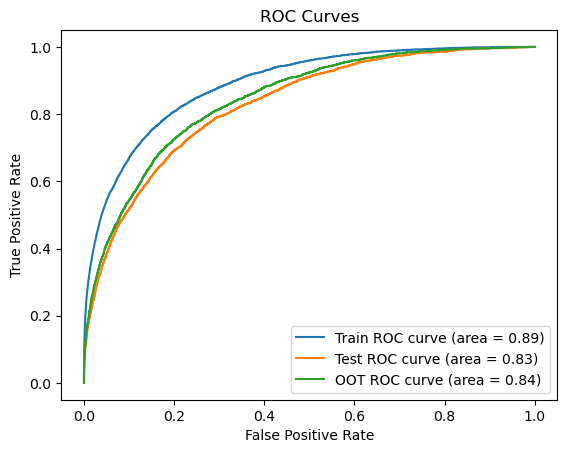

In [18]:
plt.plot(fpr_train, tpr_train, label='Train ROC curve (area = %0.2f)' % roc_auc_score(scores_train['y_true'], scores_train['y_pred']))
plt.plot(fpr_test, tpr_test, label='Test ROC curve (area = %0.2f)' % roc_auc_score(scores_test['y_true'], scores_test['y_pred']))
plt.plot(fpr_oot, tpr_oot, label='OOT ROC curve (area = %0.2f)' % roc_auc_score(scores_oot['y_true'], scores_oot['y_pred']))
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.show()

In [19]:
feature_importance_df = pd.DataFrame({
    'features': feature_vars,
    'importance': xgb_model.feature_importances_
}).sort_values(by='importance', ascending=False).reset_index(drop=True)

iv_df = pd.read_csv('../Files/iv_df.csv')[['features', 'iv_train']]
feature_importance_df = feature_importance_df.merge(iv_df, on='features', how='inner')
feature_importance_df['importance'] = feature_importance_df['importance'].apply(lambda x: f"{x:.2%}")
feature_importance_df['iv_train'] = feature_importance_df['iv_train'].apply(lambda x: f"{x:.4f}")
feature_importance_df.to_csv('../Artifacts/feature_importance_df_ratio_and_flag_features.csv', index=False)
feature_importance_df

,features,importance,iv_train
0,operating_cashflow_assets,20.02%,0.7747
1,liabilities_assets_proxy,15.00%,0.6212
2,net_profit_assets,12.64%,0.7780
3,equity_assets,7.66%,0.6212
4,cashflow_liabilities_proxy,5.88%,0.8209
5,short_term_debt_assets,5.21%,0.4948
6,operating_profit_assets,3.90%,0.6153
7,receivables_assets,3.36%,0.1371
8,sector_category,3.22%,0.0314
9,interest_coverage_proxy,2.56%,0.5556


100%|██████████| 100/100 [00:04<00:00, 22.16it/s]


Mean bootstrap AUC: 0.8443
95% confidence interval: [0.8359, 0.8525]


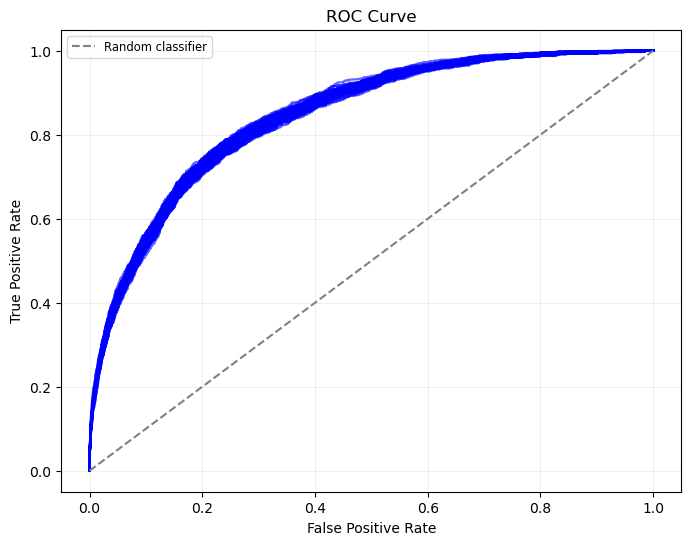

In [40]:
y = scores_oot['y_true'].to_numpy()
score = scores_oot['y_pred'].to_numpy()

n_bootstrap = 100
rng = np.random.default_rng(42)
aucs = []

plt.figure(figsize=(8, 6))

for i in tqdm(range(n_bootstrap)):
    indices = rng.choice(len(y), size=len(y), replace=True)
    y_bootstrap = y[indices]
    score_bootstrap = score[indices]

    roc_auc_bootstrap = roc_auc_score(y_bootstrap, score_bootstrap)
    aucs.append(roc_auc_bootstrap)
    fpr_bootstrap, tpr_bootstrap, _ = roc_curve(y_bootstrap, score_bootstrap)

    plt.plot(fpr_bootstrap, tpr_bootstrap, 'b', alpha=0.6)

auc_mean = np.mean(aucs)
auc_lower, auc_upper = np.percentile(aucs, [2.5, 97.5])
print(f"Mean bootstrap AUC: {auc_mean:.4f}")
print(f"95% confidence interval: [{auc_lower:.4f}, {auc_upper:.4f}]")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(fontsize="small")
plt.grid(alpha=0.2)
plt.show()